In [ ]:
import pandas as pd
df = pd.read_csv('/content/sample_data/combined_statslogExcluded_SMOTE_GenderBalancedWithCTGAN.csv')

In [ ]:

df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'target'],
      dtype='object')

In [ ]:
from sklearn.model_selection import train_test_split
X = df.drop('target',axis=1)
y = df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=123)

# SHAP XGBoost [Clinical]

/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [06:49:12] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


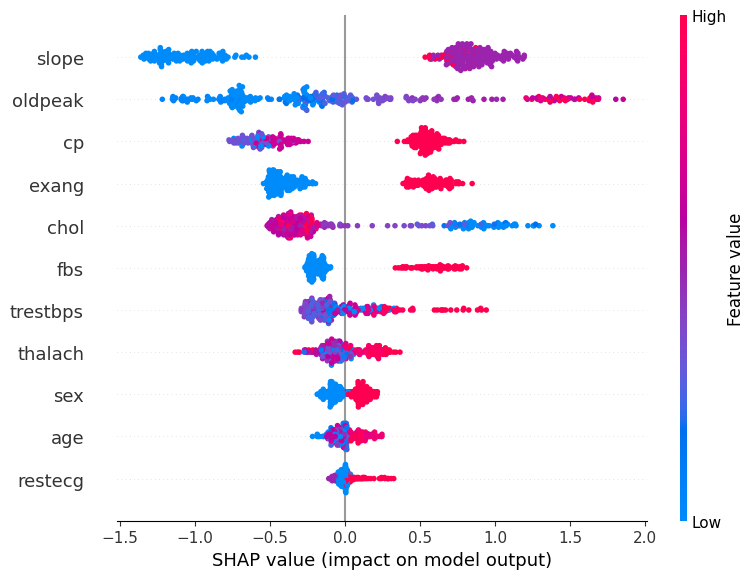

In [ ]:
import shap
import matplotlib.pyplot as plt
import xgboost as xgb

model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    use_label_encoder=False,
    n_estimators = 115, max_depth = 6, learning_rate = 0.0547, subsample = 0.5715,
    colsample_bytree = 0.5422, gamma = 1.5894, reg_alpha = 0.9968, reg_lambda = 0.8258
)
model.fit(X_train, y_train)

# Step 2: Explain model predictions using SHAP
explainer = shap.Explainer(model, X_train)
shap_values = explainer(X_test)

# Step 3: Plot SHAP summary
shap.summary_plot(shap_values, X_test)  # global impact


In [ ]:
display(X_test.iloc[[12]])
display(X_test.iloc[[9]])
print(model.predict(X_test.iloc[[12]]))
print(model.predict(X_test.iloc[[9]]))

,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope
1046,31,0,2,176,370,0,2,87,0,0.046046,2


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope
1280,65,1,4,110,248,0,2,158,0,0.6,1


[0]
[1]


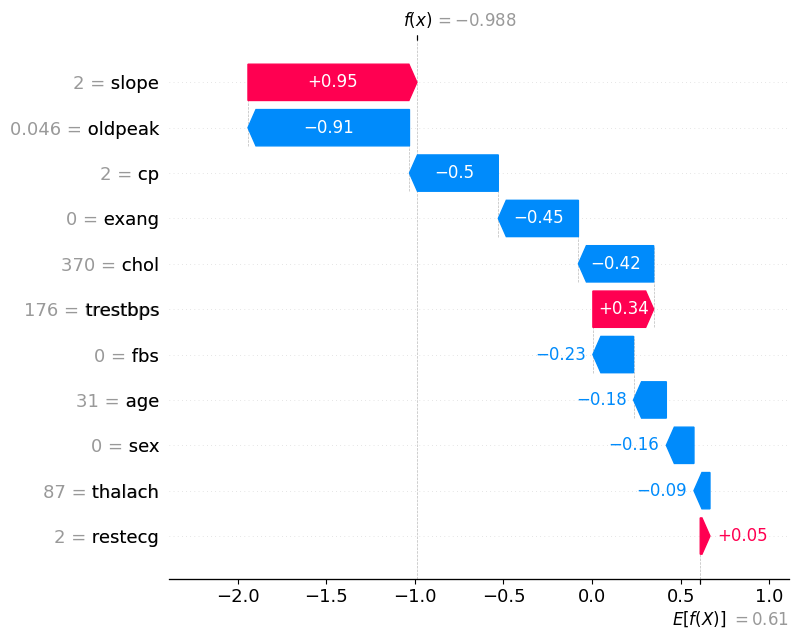

In [ ]:
# Pick a random index from X_test
random_idx = 12

# Plot the explanation for the selected patient
shap.plots.waterfall(shap_values[random_idx], max_display=11)


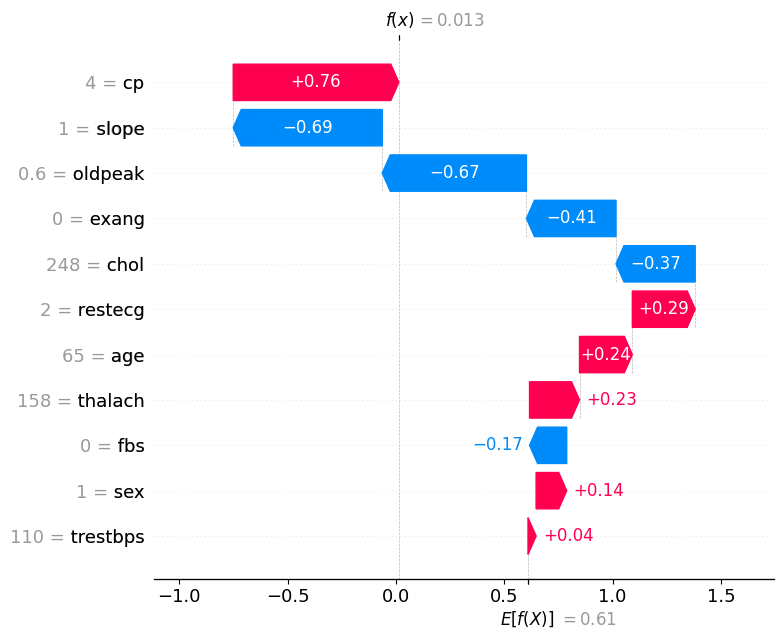

In [ ]:
# Pick a random index from X_test
random_idx = 9

# Plot the explanation for the selected patient
shap.plots.waterfall(shap_values[random_idx], max_display=11)


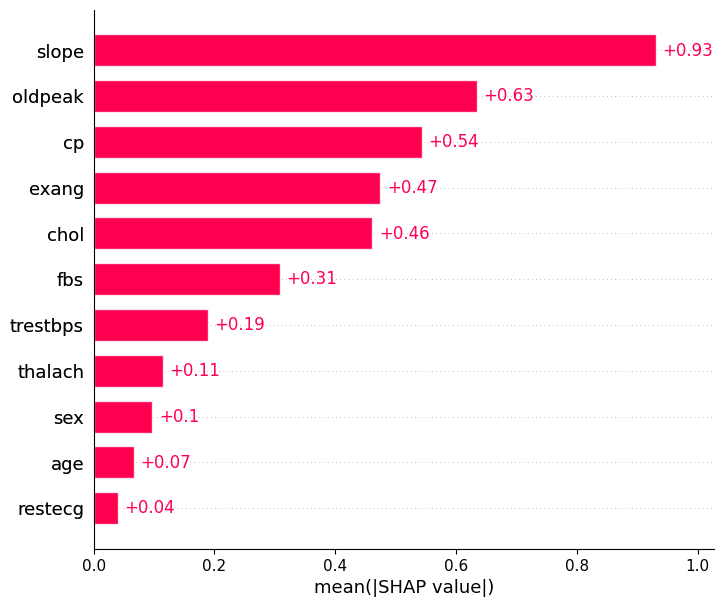

In [ ]:
# Bar plot of mean(|SHAP value|) per feature
shap.plots.bar(shap_values, max_display=11)

# SHAP RF [Non-Clinical]

In [ ]:
reduced_df = df.drop(columns=['chol','restecg','oldpeak','slope'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=123)

In [ ]:
# Fit Random Forest
model = RandomForestClassifier(
    n_estimators=110, max_depth=20, min_samples_split=4,
    min_samples_leaf=8, max_features='sqrt', bootstrap=True
)
model.fit(X_train, y_train)



RandomForestClassifier(max_depth=20, min_samples_leaf=8, min_samples_split=4,
                       n_estimators=110)

In [ ]:
def f(x):
    return model.predict_proba(x)[:, 1]


med = X_train.median().values.reshape((1, X_train.shape[1]))

explainer = shap.Explainer(f, med)
shap_values = explainer(X_test.iloc[0:1000, :])

In [ ]:
print(model.predict(X_test.iloc[[12]]))
print(model.predict(X_test.iloc[[9]]))

[0]
[1]


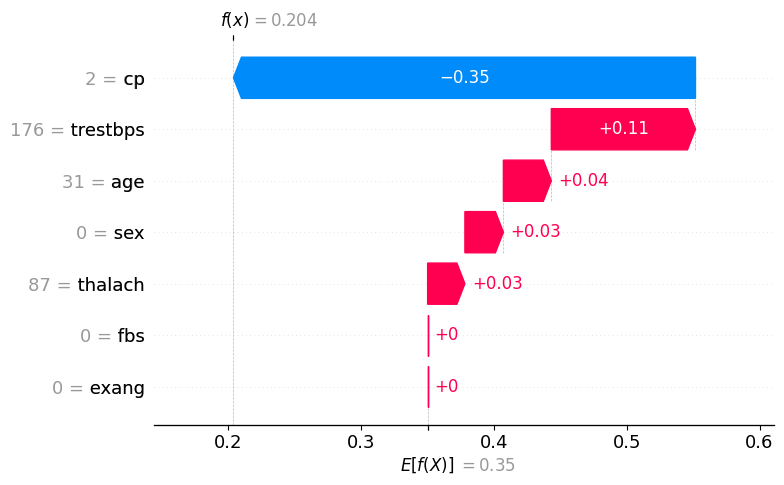

In [ ]:
shap.plots.waterfall(shap_values[12])

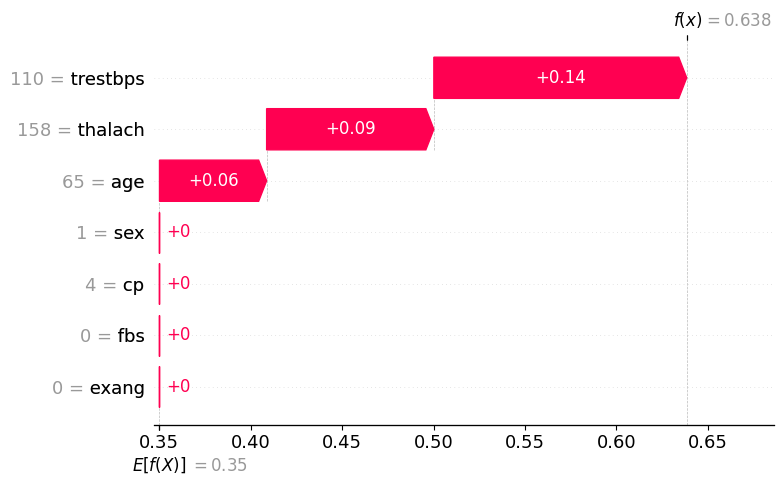

In [ ]:
shap.plots.waterfall(shap_values[9])

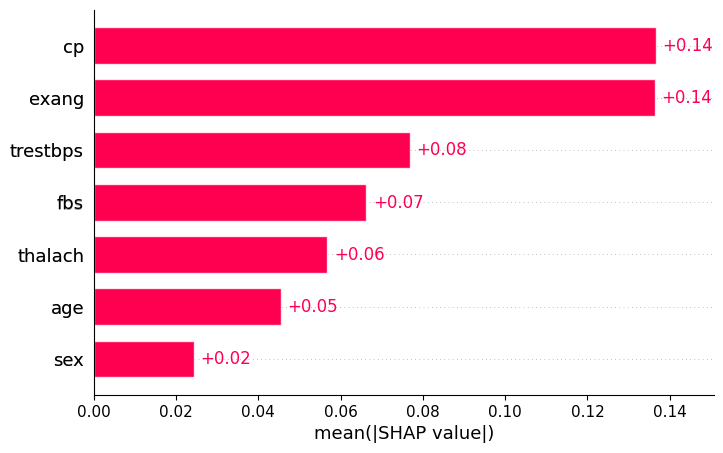

In [ ]:
# Bar plot of mean(|SHAP value|) per feature
shap.plots.bar(shap_values, max_display=11)

# DiCE XGBoost [Clinical]

In [ ]:
!pip install dice-ml

In [ ]:
import dice_ml
from dice_ml import Dice
from dice_ml.utils import helpers

In [ ]:
df.dtypes

In [ ]:

import matplotlib.pyplot as plt
import xgboost as xgb

model = xgb.XGBClassifier(
    objective="binary:logistic",
    eval_metric="logloss",
    use_label_encoder=False,
    n_estimators = 115, max_depth = 6, learning_rate = 0.0547, subsample = 0.5715,
    colsample_bytree = 0.5422, gamma = 1.5894, reg_alpha = 0.9968, reg_lambda = 0.8258,
    enable_categorical = True
)
model.fit(X_train, y_train)




/usr/local/lib/python3.11/dist-packages/xgboost/core.py:158: UserWarning: [12:21:26] WARNING: /workspace/src/learner.cc:740: 
Parameters: { "use_label_encoder" } are not used.

  warnings.warn(smsg, UserWarning)


XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=0.5422, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric='logloss',
              feature_types=None, gamma=1.5894, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=0.0547, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=6,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=115,
              n_jobs=None, num_parallel_tree=None, random_state=None, ...)

In [ ]:
df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'chol', 'fbs', 'restecg', 'thalach',
       'exang', 'oldpeak', 'slope', 'target'],
      dtype='object')

In [ ]:
# Define the target
target = 'target'

# List your continuous and categorical features
continuous_features = ['age', 'trestbps', 'chol', 'thalach', 'oldpeak', 'sex', 'cp', 'fbs', 'restecg', 'exang', 'slope']
categorical_features = []


# DiCE data object
data_dice = dice_ml.Data(dataframe=df,
                         continuous_features=continuous_features,
                         outcome_name=target)

# Wrap trained model (sklearn RandomForestClassifier or others)
model_dice = dice_ml.Model(model=model, backend='sklearn')

# DiCE explainer
exp = Dice(data_dice, model_dice)

# Choose a sample from test set
sample = X_test.iloc[[0]]

print("Original prediction:", model.predict(sample))  # should be 0 or 1

# Generate counterfactuals
dice_exp = exp.generate_counterfactuals(sample, total_CFs=6, desired_class="opposite")

# Display them
dice_exp.visualize_as_dataframe()

Original prediction: [1]


100%|██████████| 1/1 [00:00<00:00,  6.68it/s]

Query instance (original outcome : 1)



/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: Index.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access
/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: RangeIndex.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
0,38,1,4,110,289,0,0,105,1,1.5,3,1



Diverse Counterfactual set (new outcome: 0)


/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: Index.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access
/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: RangeIndex.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,target
0,38,1,1,110,289,0,0,105,0,1.5,3,0
1,38,1,4,110,289,0,0,105,0,1.5,0,0
2,38,1,4,110,289,0,0,105,1,-1.5,0,0
3,38,1,4,110,289,0,0,105,1,-1.3,1,0
4,38,1,3,110,289,0,0,105,1,1.5,0,0
5,38,1,4,110,289,0,0,105,0,1.5,1,0


# DiCE RF [Non-Clinical]

In [ ]:
reduced_df = df.drop(columns=['chol','restecg','slope', 'oldpeak'],axis=1)
X = reduced_df.drop('target',axis=1)
y = reduced_df['target']
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,stratify=y,random_state=123)
X

/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: Index.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access


,age,sex,cp,trestbps,fbs,thalach,exang
0,54,1,1,122,0,162,0
1,40,0,4,150,0,130,0
2,74,1,1,145,1,116,1
3,46,1,4,110,0,125,1
4,57,1,4,140,0,148,0
...,...,...,...,...,...,...,...
1537,65,1,4,145,1,67,0
1538,53,0,1,120,0,137,0
1539,45,0,4,124,0,174,1
1540,45,0,2,130,0,170,0


In [ ]:
rfc_clf = RandomForestClassifier(n_estimators=110, max_depth=20, min_samples_split=4, min_samples_leaf=8,
                                 max_features='sqrt',bootstrap=True)
rfc_clf.fit(X_train, y_train)

RandomForestClassifier(max_depth=20, min_samples_leaf=8, min_samples_split=4,
                       n_estimators=110)

In [ ]:
reduced_df.columns

Index(['age', 'sex', 'cp', 'trestbps', 'fbs', 'thalach', 'exang', 'target'], dtype='object')

In [ ]:
# Define the target
target = 'target'

# List your continuous and categorical features
continuous_features = ['age', 'sex', 'cp', 'trestbps', 'fbs', 'thalach', 'exang']
categorical_features = []


# DiCE data object
data_dice = dice_ml.Data(dataframe=reduced_df,
                         continuous_features=continuous_features,
                         outcome_name=target)

# Wrap trained model (sklearn RandomForestClassifier or others)
model_dice = dice_ml.Model(model=rfc_clf, backend='sklearn')

# DiCE explainer
exp = Dice(data_dice, model_dice)

# Choose a sample from test set
sample = X_test.iloc[[0]]

print("Original prediction:", rfc_clf.predict(sample))  # should be 0 or 1

# Generate counterfactuals
dice_exp = exp.generate_counterfactuals(sample, total_CFs=6, desired_class="opposite")

# Display them
dice_exp.visualize_as_dataframe()

Original prediction: [1]


100%|██████████| 1/1 [00:00<00:00,  4.51it/s]

Query instance (original outcome : 1)



/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: Index.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access
/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: RangeIndex.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access


,age,sex,cp,trestbps,fbs,thalach,exang,target
0,38,1,4,110,0,105,1,1



Diverse Counterfactual set (new outcome: 0)


/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: Index.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access
/usr/local/lib/python3.11/dist-packages/google/colab/_interactive_table_hint_button.py:178: FutureWarning: RangeIndex.format is deprecated and will be removed in a future version. Convert using index.astype(str) or index.map(formatter) instead.
  df_html=dataframe._repr_html_(),  # pylint: disable=protected-access


,age,sex,cp,trestbps,fbs,thalach,exang,target
0,38,1,1,110,0,105,0,0
1,29,1,4,110,0,105,0,0
2,28,1,4,110,0,105,0,0
3,38,1,4,110,0,199,0,0
4,38,1,2,110,0,105,0,0
5,38,1,4,110,0,183,0,0


# Next: We are entering into the boss level. Tabular Neural Models.
https://colab.research.google.com/drive/11bDv8obml4qHmCoT4-E0sGvnzQy3r8VV?usp=sharing